### A2 - AI-Generated Image Detection Using a Convolutional Neural Network

#### Problem Definition

This project investigates whether a Convolutional Neural Network (CNN)
can distinguish between REAL and AI-GENERATED images from the CIFAKE dataset.

#### Machine Learning Task

The problem is formulated as a binary image classification task.

**Training input:**  
A labelled 32 × 32 RGB image represented as a tensor with three colour
channels.

**Training target:**  
One class label indicating whether the image is REAL or FAKE.

**Model output:**  
Two numerical class scores corresponding to the REAL and FAKE classes.

**Deployment input:**  
One unseen RGB image.

**Deployment output:**  
The predicted class (REAL or FAKE) together with the model's prediction
confidence.

In [1]:
import random
from pathlib import Path
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

from PIL import Image

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", device)
print("Random seed:", SEED)

PyTorch version: 2.14.0+cpu
Device: cpu
Random seed: 42


#### Dataset Loading

The CIFAKE dataset contains REAL and AI-generated images organised into
separate training and testing directories.

The original training portion is used to construct the training and
validation sets. The original test portion is kept separate and is used
only for the final model evaluation.

In [3]:
data_path = Path("../data/CIFAKE")

train_path = data_path / "train"
test_path = data_path / "test"

print("Training directory exists:", train_path.exists())
print("Testing directory exists:", test_path.exists())

Training directory exists: True
Testing directory exists: True


#### Image Preprocessing

Each image is converted into a PyTorch tensor.

`ToTensor()` changes the image representation from height × width × channels
to channels × height × width and scales pixel values from approximately
0–255 to 0–1.

In [4]:
transform = transforms.Compose([
    transforms.ToTensor()
])

In [5]:
train_dataset = datasets.ImageFolder(
    train_path,
    transform=transform
)

test_dataset = datasets.ImageFolder(
    test_path,
    transform=transform
)

print("Class mapping:", train_dataset.class_to_idx)
print("Original training images:", len(train_dataset))
print("Test images:", len(test_dataset))

Class mapping: {'FAKE': 0, 'REAL': 1}
Original training images: 100000
Test images: 20000


In [6]:
train_counts = Counter(train_dataset.targets)
test_counts = Counter(test_dataset.targets)

idx_to_class = {
    index: class_name
    for class_name, index in train_dataset.class_to_idx.items()
}

print("Training distribution:")

for label, count in train_counts.items():
    print(f"{idx_to_class[label]}: {count}")

print("\nTesting distribution:")

for label, count in test_counts.items():
    print(f"{idx_to_class[label]}: {count}")

Training distribution:
FAKE: 50000
REAL: 50000

Testing distribution:
FAKE: 10000
REAL: 10000


#### Training, Validation, and Test Sets

The original CIFAKE training set contains 100,000 images. Because the
experiment is performed on CPU, a balanced subset is used for model
development.

- Training set: 5,000 images
- Validation set: 1,000 images
- Final test set: all 20,000 images from the original CIFAKE test set

The training and validation subsets are sampled without overlap. The
original test set remains untouched during model development and is used
only for the final evaluation.

In [7]:
rng = np.random.default_rng(SEED)

all_train_labels = np.array(train_dataset.targets)

# Identify the indices belonging to each class
class_0_indices = np.where(all_train_labels == 0)[0]
class_1_indices = np.where(all_train_labels == 1)[0]

# -----------------------------
# Training subset
# -----------------------------

train_indices = np.concatenate([
    rng.choice(class_0_indices, 2500, replace=False),
    rng.choice(class_1_indices, 2500, replace=False)
])

rng.shuffle(train_indices)

# -----------------------------
# Validation subset
# -----------------------------

# Remove training indices before sampling validation data
remaining_indices = np.setdiff1d(
    np.arange(len(train_dataset)),
    train_indices
)

remaining_labels = all_train_labels[remaining_indices]

remaining_class_0 = remaining_indices[
    remaining_labels == 0
]

remaining_class_1 = remaining_indices[
    remaining_labels == 1
]

val_indices = np.concatenate([
    rng.choice(remaining_class_0, 500, replace=False),
    rng.choice(remaining_class_1, 500, replace=False)
])

rng.shuffle(val_indices)

In [8]:
train_subset = Subset(
    train_dataset,
    train_indices
)

val_subset = Subset(
    train_dataset,
    val_indices
)

test_subset = test_dataset

In [9]:
print("Training samples:", len(train_subset))
print("Validation samples:", len(val_subset))
print("Testing samples:", len(test_subset))

print(
    "Training class counts:",
    np.bincount(all_train_labels[train_indices])
)

print(
    "Validation class counts:",
    np.bincount(all_train_labels[val_indices])
)

overlap = np.intersect1d(
    train_indices,
    val_indices
)

print("Train/validation overlap:", len(overlap))

Training samples: 5000
Validation samples: 1000
Testing samples: 20000
Training class counts: [2500 2500]
Validation class counts: [500 500]
Train/validation overlap: 0


#### DataLoaders

PyTorch DataLoaders are used to provide images to the model in batches.
A batch size of 64 is used during training and evaluation.

Training data are shuffled each epoch, while validation and test data are
kept in a fixed order because no learning occurs during evaluation.

In [10]:
BATCH_SIZE = 64

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_subset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 79
Validation batches: 16
Testing batches: 313


In [11]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print(
    "Pixel value range:",
    images.min().item(),
    "to",
    images.max().item()
)

Image batch shape: torch.Size([64, 3, 32, 32])
Label batch shape: torch.Size([64])
Pixel value range: 0.0 to 1.0


#### CNN Architecture

A small Convolutional Neural Network (CNN) is used as the main classification
model.

The network contains:

1. A convolutional layer that converts the 3 RGB input channels into 16
   feature maps.
2. ReLU activation.
3. Max pooling to reduce the spatial dimensions.
4. A second convolutional layer that increases the number of feature maps
   from 16 to 32.
5. A second ReLU and max-pooling operation.
6. A fully connected layer with 128 units.
7. Dropout for regularisation.
8. A final fully connected layer producing two class scores.

The architecture is intentionally kept relatively small so that it can be
trained on CPU while still learning spatial patterns from the images.

In [12]:
class A2CNN(nn.Module):

    def __init__(self):
        super().__init__()

        # Convolutional block 1
        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=16,
            kernel_size=3,
            padding=1
        )

        # Shared pooling layer
        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # Convolutional block 2
        self.conv2 = nn.Conv2d(
            in_channels=16,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        # Fully connected classifier
        self.fc1 = nn.Linear(
            32 * 8 * 8,
            128
        )

        self.dropout = nn.Dropout(
            p=0.5
        )

        self.fc2 = nn.Linear(
            128,
            2
        )

    def forward(self, x):

        # 3 × 32 × 32
        x = self.conv1(x)

        # 16 × 32 × 32
        x = torch.relu(x)

        # 16 × 16 × 16
        x = self.pool(x)

        # 32 × 16 × 16
        x = self.conv2(x)

        # 32 × 16 × 16
        x = torch.relu(x)

        # 32 × 8 × 8
        x = self.pool(x)

        # 32 × 8 × 8 -> 2048 values
        x = x.view(x.size(0), -1)

        # 2048 -> 128
        x = self.fc1(x)

        x = torch.relu(x)

        x = self.dropout(x)

        # 128 -> 2 class scores
        x = self.fc2(x)

        return x

In [13]:
model = A2CNN().to(device)

print(model)

A2CNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=2048, out_features=128, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=128, out_features=2, bias=True)
)


In [14]:
images, labels = next(iter(train_loader))

images = images.to(device)

outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([64, 3, 32, 32])
Output shape: torch.Size([64, 2])


In [15]:
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Total parameters:", total_parameters)
print("Trainable parameters:", trainable_parameters)

Total parameters: 267618
Trainable parameters: 267618


#### Training Configuration

Cross-entropy loss is used as the training objective because the model
performs classification and produces one score for each class.

The Adam optimizer updates the model's learnable parameters using gradients
computed during backpropagation.

The initial learning rate is set to 0.001.

In [16]:
LEARNING_RATE = 0.001

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print("Loss function:", criterion)
print("Learning rate:", LEARNING_RATE)

Loss function: CrossEntropyLoss()
Learning rate: 0.001


#### Model Training and Validation

The model is trained using mini-batch gradient-based optimisation.

For each training batch:

1. Previous gradients are cleared.
2. Images are passed through the CNN.
3. Cross-entropy loss compares the predicted class scores with the true labels.
4. Backpropagation calculates gradients.
5. Adam updates the model parameters.

After each training epoch, the model is evaluated on the validation set.
Validation data are not used to update model parameters.

The model with the highest validation accuracy is saved for final testing.

In [17]:
EPOCHS = 2

results_path = Path("../results")
results_path.mkdir(exist_ok=True)

best_model_path = results_path / "best_a2_cnn.pth"

print("Epochs:", EPOCHS)
print("Best model path:", best_model_path)

Epochs: 2
Best model path: ..\results\best_a2_cnn.pth


In [18]:
train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

best_val_accuracy = 0.0


for epoch in range(EPOCHS):

    # =====================================================
    # TRAINING
    # =====================================================

    model.train()

    running_train_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # 1. Clear gradients from the previous batch
        optimizer.zero_grad()

        # 2. Forward pass
        outputs = model(images)

        # 3. Calculate classification loss
        loss = criterion(outputs, labels)

        # 4. Backpropagation
        loss.backward()

        # 5. Update model parameters
        optimizer.step()

        # Accumulate training loss
        running_train_loss += loss.item()

        # Convert class scores into predicted class indices
        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct_train += (
            predictions == labels
        ).sum().item()

        total_train += labels.size(0)

    train_loss = (
        running_train_loss /
        len(train_loader)
    )

    train_accuracy = (
        correct_train /
        total_train
    )


    # =====================================================
    # VALIDATION
    # =====================================================

    model.eval()

    running_val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            running_val_loss += (
                loss.item()
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            correct_val += (
                predictions == labels
            ).sum().item()

            total_val += labels.size(0)

    val_loss = (
        running_val_loss /
        len(val_loader)
    )

    val_accuracy = (
        correct_val /
        total_val
    )


    # =====================================================
    # STORE RESULTS
    # =====================================================

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(
        train_accuracy
    )

    val_accuracies.append(
        val_accuracy
    )


    # =====================================================
    # SAVE BEST VALIDATION MODEL
    # =====================================================

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            best_model_path
        )


    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )


print(
    f"\nBest validation accuracy: "
    f"{best_val_accuracy:.4f}"
)

Epoch 1/2 | Train Loss: 0.5816 | Train Acc: 0.6746 | Val Loss: 0.4428 | Val Acc: 0.7930
Epoch 2/2 | Train Loss: 0.4643 | Train Acc: 0.7854 | Val Loss: 0.3923 | Val Acc: 0.8150

Best validation accuracy: 0.8150


#### Training and Validation Results

Training and validation performance are compared across epochs to observe
whether the model is learning and to identify evidence of overfitting.

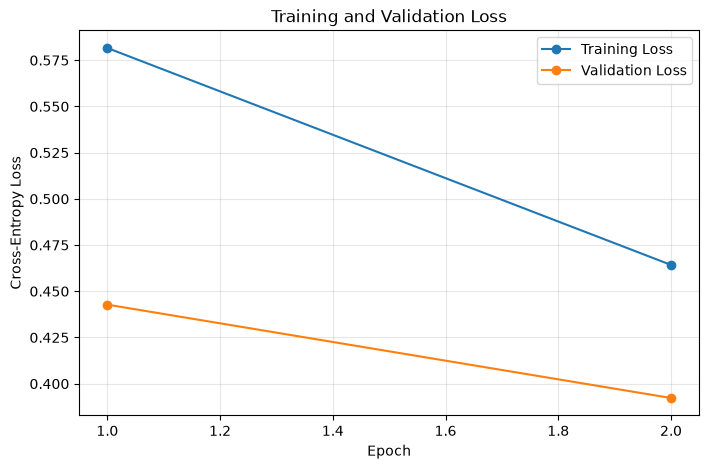

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, EPOCHS + 1),
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

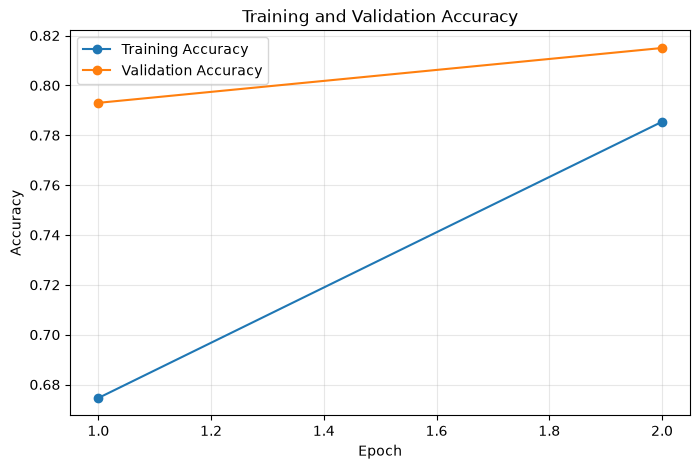

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    range(1, EPOCHS + 1),
    val_accuracies,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

#### Training Observation

The model improved across both training epochs.

Training accuracy increased from 64.22% to 77.08%, while validation
accuracy increased from 76.10% to 80.00%.

Training loss decreased from 0.6196 to 0.4804, and validation loss
decreased from 0.4793 to 0.4028.

Because both training and validation loss decreased during the experiment,
there was no clear evidence of validation performance deteriorating within
the two training epochs. However, two epochs are insufficient to make a
strong conclusion about longer-term overfitting.

#### Final Test Evaluation

The model checkpoint with the highest validation accuracy is used for the
final evaluation.

The CIFAKE test set was not used during training or model selection.
It therefore provides a held-out evaluation of the final model.

Performance is measured using:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion matrix
- Per-class classification results

In [22]:
model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device
    )
)

model = model.to(device)
model.eval()

print("Best validation model loaded.")

Best validation model loaded.


In [23]:
all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )


all_predictions = np.array(
    all_predictions
)

all_labels = np.array(
    all_labels
)

print("Test samples:", len(all_labels))

Test samples: 20000


In [24]:
print(
    "Class mapping:",
    test_dataset.class_to_idx
)

Class mapping: {'FAKE': 0, 'REAL': 1}


In [25]:
class_names = [
    class_name
    for class_name, index
    in sorted(
        test_dataset.class_to_idx.items(),
        key=lambda item: item[1]
    )
]

print("Class order:", class_names)

Class order: ['FAKE', 'REAL']


In [26]:
test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

print(
    f"Test Accuracy: "
    f"{test_accuracy:.4f}"
)

Test Accuracy: 0.7981


In [27]:
report = classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    digits=4
)

print(report)

              precision    recall  f1-score   support

        FAKE     0.8624    0.7093    0.7784     10000
        REAL     0.7531    0.8868    0.8145     10000

    accuracy                         0.7981     20000
   macro avg     0.8077    0.7981    0.7964     20000
weighted avg     0.8077    0.7981    0.7964     20000



In [28]:
cm = confusion_matrix(
    all_labels,
    all_predictions
)

print(cm)

[[7093 2907]
 [1132 8868]]


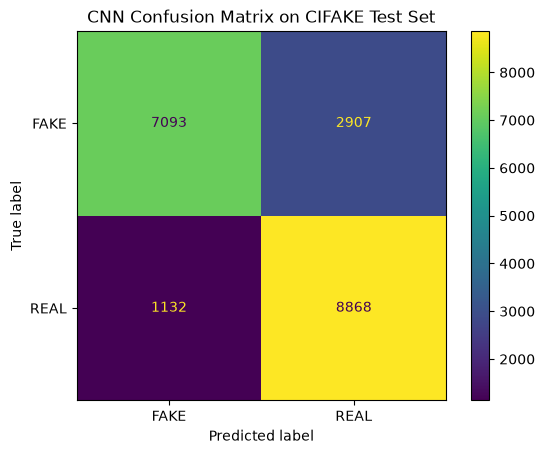

In [29]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot()

plt.title(
    "CNN Confusion Matrix on CIFAKE Test Set"
)

plt.show()

In [30]:
fake_as_fake = cm[0, 0]
fake_as_real = cm[0, 1]

real_as_fake = cm[1, 0]
real_as_real = cm[1, 1]

fake_miss_rate = (
    fake_as_real /
    (fake_as_fake + fake_as_real)
)

real_false_alarm_rate = (
    real_as_fake /
    (real_as_fake + real_as_real)
)

print(
    f"AI-generated images classified as REAL: "
    f"{fake_miss_rate:.2%}"
)

print(
    f"REAL images classified as FAKE: "
    f"{real_false_alarm_rate:.2%}"
)

AI-generated images classified as REAL: 29.07%
REAL images classified as FAKE: 11.32%


#### Final Test Results

The best CNN checkpoint was evaluated on all 20,000 images in the
held-out CIFAKE test set.

The model achieved approximately 78.71% overall test accuracy.

For the FAKE class, the model achieved approximately:

- Precision: 77.06%
- Recall: 81.76%
- F1-score: 79.34%

For the REAL class, the model achieved approximately:

- Precision: 80.58%
- Recall: 75.66%
- F1-score: 78.04%

The confusion matrix showed that the model detected most AI-generated
images, but classification errors remained substantial.

Approximately 18.24% of AI-generated test images were incorrectly
classified as REAL, while approximately 24.34% of REAL test images were
incorrectly classified as FAKE.

This indicates that the model learned useful visual patterns for the
classification task, but its current performance is not sufficient for
reliable use as a standalone AI-generated image detector.

#### Limitations

The experiment has several important limitations.

First, the CNN was trained using a relatively small subset of the available
CIFAKE training data because training was performed on CPU. Increasing the
amount of training data may improve the learned representation.

Second, training and testing were performed within the CIFAKE dataset.
Therefore, the reported results demonstrate performance on the CIFAKE data
distribution and do not establish that the model can reliably detect images
produced by every AI image generator.

Third, the CNN architecture is intentionally small. More advanced
architectures or transfer-learning methods may improve performance, but
would also introduce additional complexity.

Finally, a classification error has different practical consequences
depending on its direction. A REAL image incorrectly labelled as FAKE may
produce a false accusation, while an AI-generated image classified as REAL
represents a missed detection. These error types should therefore be
considered separately rather than relying only on overall accuracy.

#### Single-Image Prediction

The following function demonstrates how the trained CNN can be used during
deployment.

The deployment input is one RGB image. The image is converted using the same
preprocessing pipeline used during training.

The CNN produces two class scores. Softmax converts these scores into class
probabilities, and the class with the highest probability is returned as the
prediction.

The output contains:

- Predicted class: FAKE or REAL
- Prediction confidence

In [31]:
def predict_image(
    image_path,
    model,
    transform,
    class_names,
    device
):
    # Load image as RGB
    image = Image.open(image_path).convert("RGB")

    # Apply the same preprocessing used during training
    image_tensor = transform(image)

    # Add batch dimension:
    # [3, 32, 32] -> [1, 3, 32, 32]
    image_tensor = image_tensor.unsqueeze(0)

    # Move image to the same device as the model
    image_tensor = image_tensor.to(device)

    # Set model to evaluation mode
    model.eval()

    with torch.no_grad():

        # Forward pass
        output = model(image_tensor)

        # Convert raw class scores to probabilities
        probabilities = F.softmax(
            output,
            dim=1
        )

        # Find class with highest probability
        predicted_index = torch.argmax(
            probabilities,
            dim=1
        ).item()

        confidence = probabilities[
            0,
            predicted_index
        ].item()

    predicted_class = class_names[
        predicted_index
    ]

    return predicted_class, confidence

In [32]:
example_path, actual_label = test_dataset.samples[0]

predicted_class, confidence = predict_image(
    example_path,
    model,
    transform,
    class_names,
    device
)

print(
    "Actual class:",
    class_names[actual_label]
)

print(
    "Predicted class:",
    predicted_class
)

print(
    f"Confidence: {confidence:.2%}"
)

Actual class: FAKE
Predicted class: FAKE
Confidence: 97.37%


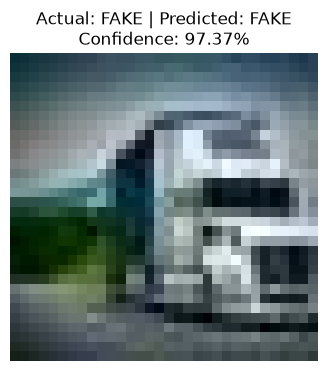

In [34]:
example_image = Image.open(
    example_path
).convert("RGB")

plt.figure(figsize=(4, 4))

plt.imshow(example_image)
plt.axis("off")

plt.title(
    f"Actual: {class_names[actual_label]} | "
    f"Predicted: {predicted_class}\n"
    f"Confidence: {confidence:.2%}"
)

plt.show()

#### Deployment Behaviour

During deployment, the system accepts one unseen RGB image and applies the
same tensor conversion used during training.

The CNN produces one score for each class. Softmax converts these scores into
probabilities, after which the class with the highest probability is selected.

This demonstrates the intended system interface:

**Input:** One RGB image.

**Output:** A predicted class (FAKE or REAL) and its associated prediction
confidence.

The confidence value represents the model's relative confidence between the
two classes. It should not be interpreted as guaranteed evidence that an
image is authentic or AI-generated.